# Overlay a crop dataset on an environmental layer

Choose a crop and a static or TraCE layer. The layer is loaded over the crop file extent, which already includes the configured padding. Crop points are colored by time. Run the cells from top to bottom.

In [1]:
# Import plotting, HDF5, numerical, and project loading tools.
from pathlib import Path
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Find the repository root whether Jupyter starts in the root or the python folder.
working_directory = Path.cwd().resolve()
root_candidates = (working_directory, *working_directory.parents)
PROJECT_ROOT = next(
    (candidate for candidate in root_candidates
     if (candidate / "python" / "convert_layers_to_hdf5.py").exists()
     and (candidate / "data" / "processed").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the repository root from the notebook working directory.")

# Import the root-level layer loader used by the current project.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from load_layers import load_layer


In [ ]:
# Choose one crop file and one layer file to compare.
crop_name = "wheat"
layer_name = "prec"

# Read layers from the converter output directory and crops from its crop subfolder.
CROP_DIRECTORY = PROJECT_ROOT / "data" / "processed" / "crop"
LAYER_DIRECTORY = PROJECT_ROOT / "data" / "processed"


In [ ]:
# Read the crop point arrays and their stored padded extents from its HDF5 file.
crop_path = CROP_DIRECTORY / f"{crop_name}.h5"
with h5py.File(crop_path, "r") as crop_file:
    crop_data = {
        name: crop_file[name][()]
        for name in ("lat", "lon", "time", "lat_extent", "lon_extent")
    }

# Use the crop's observed time range for trace layers; static layers ignore it.
year_extent = (float(crop_data["time"].min()), float(crop_data["time"].max()))
latitude_extent = tuple(np.asarray(crop_data["lat_extent"], dtype=float))
longitude_extent = tuple(np.asarray(crop_data["lon_extent"], dtype=float))
layer_data = load_layer(
    layer_name,
    latitude_extent,
    longitude_extent,
    year_extent=year_extent if layer_name in {"temp", "prec"} else None,
    layer_directory=LAYER_DIRECTORY,
)

# Report the selected bounds and shapes before plotting.
print(f"Crop: {crop_name}; observations: {len(crop_data['lat']):,}")
print(f"Crop padded extent (degrees): latitude={latitude_extent}, longitude={longitude_extent}")
print(f"Layer: {layer_name}; grid shape={layer_data['data'].shape}")
print(f"Layer coordinate lengths: lat={len(layer_data['lat'])}, lon={len(layer_data['lon'])}")
if "years" in layer_data:
    print(f"Layer years averaged: {layer_data['years'].min():g} to {layer_data['years'].max():g}")


Crop: wheat; observations: 908
Crop padded extent (degrees): latitude=(np.float64(7.2166999999999994), np.float64(64.35)), longitude=(np.float64(-14.82), np.float64(93.083905))
Layer: csi; grid shape=(685, 1295)
Layer coordinate lengths: lat=685, lon=1295


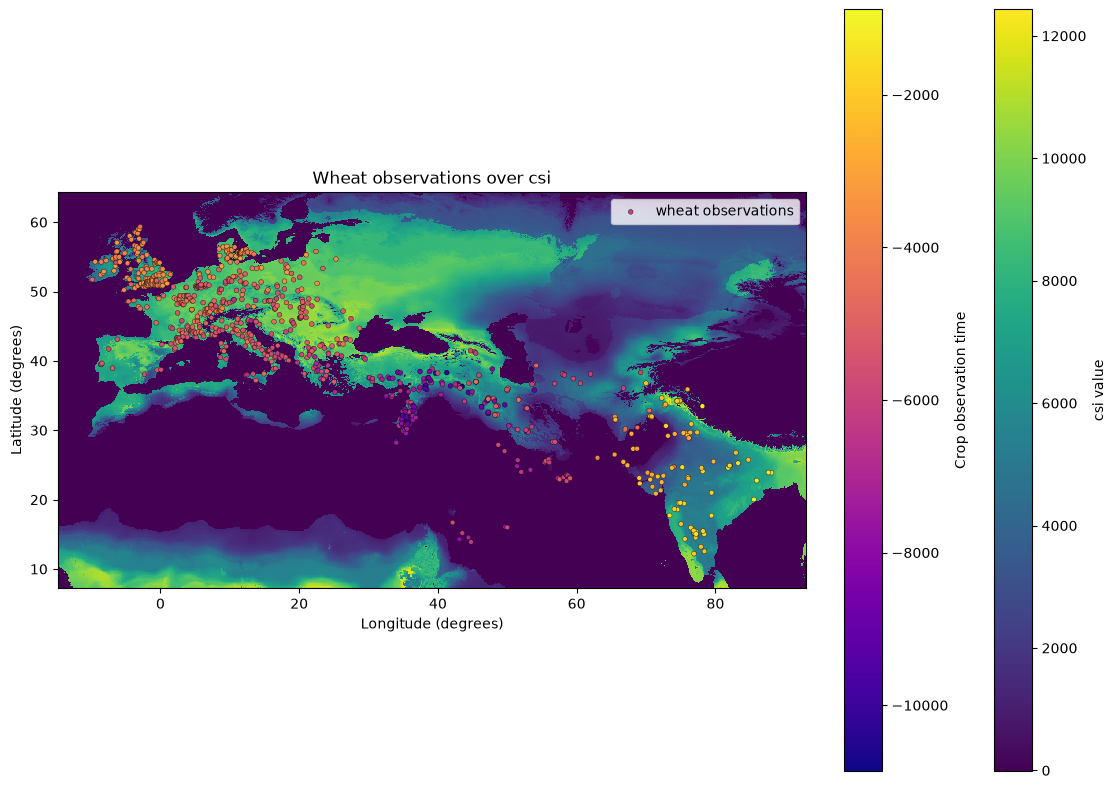

In [17]:
# Draw the environmental grid first, then overlay crop observations colored by their dates.
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
mesh = ax.pcolormesh(
    layer_data['lon'],
    layer_data['lat'],
    np.ma.masked_invalid(layer_data['data']),
    shading='auto',
    cmap='viridis',
)
fig.colorbar(mesh, ax=ax, label=f'{layer_name} value')
points = ax.scatter(
    crop_data['lon'],
    crop_data['lat'],
    c=crop_data['time'],
    cmap='plasma',
    s=12,
    edgecolors='black',
    linewidths=0.25,
    label=f'{crop_name} observations',
)
fig.colorbar(points, ax=ax, label='Crop observation time')
ax.set_xlim(longitude_extent)
ax.set_ylim(latitude_extent)
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Latitude (degrees)')
ax.set_title(f'{crop_name.capitalize()} observations over {layer_name}')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='best')
plt.show()